# Workshop 1 — Source Profiling Notebook
**Team 4 · Tropical Cyclone Monitoring · Data Analysis Programming 2026-II**

This notebook validates the four selected sources with **real queries**, profiles at least 200 records per source,
documents data-quality problems with example records, checks cross-source overlap, and estimates historical volume.

| ID | Role | Source |
|---|---|---|
| S1 | Historical 1 | IBTrACS v04r01 `since1980` (CSV) |
| S2 | Historical 2 | GDACS tropical-cyclone events, archive window (REST / GeoJSON) |
| S3 | Incremental 1 | IBTrACS v04r01 `ACTIVE` (CSV + HTTP validators) |
| S4 | Incremental 2 | GDACS tropical-cyclone events, last 7 days (REST / GeoJSON) |
| S5 | Optional | NHC `CurrentStorms.json` (Atlantic and E/C Pacific only) |

**How to run.** From the repository root: `pip install -r requirements.txt`, copy `.env.example` to `.env`
and set `TCMON_USER_AGENT` with a contact e-mail, then *Run All*. Execute top to bottom and commit the notebook **with outputs**.

**Evidence policy.** Raw responses are stored unmodified with a `.meta.json` (URL, UTC time, status, headers, SHA-256).
Large files stay in `data/raw/` (git-ignored); small files and verbatim heads go to `workshop_1/samples/`.
Results are written to `workshop_1/evidence/` and copied into the report.

In [33]:
import json, sys, glob
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "workshop_1" / "tools"))

from tcmon.config import raw_dir, user_agent
from tcmon.http_client import PoliteClient
from tcmon.sources import gdacs, ibtracs, nhc
from tcmon.normalization import canonical
from tcmon.normalization.units import haversine_km, KMH_PER_KT

SAMPLES = ROOT / "workshop_1" / "samples"
EVIDENCE = ROOT / "workshop_1" / "evidence"
EVIDENCE.mkdir(parents=True, exist_ok=True)
RAW = raw_dir()

FETCH = False          # set False to re-profile already downloaded files without new requests
GDACS_YEAR = 2024     # archive window used for S2 profiling and the overlap check
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
print("Run at (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("User-Agent :", user_agent())

Run at (UTC): 2026-11-14T19:05:37+00:00
User-Agent : TC-Analog-Monitor/0.1 (Universidad Distrital, Team 4; contact: oepenas@udistrital.edu.co)


## 1. Real queries (evidence collection)
`collect_samples.run()` queries every source once and saves each response unmodified. The table below is the
**evidence of access**: HTTP status, size, validators and time of each request.

In [34]:
from collect_samples import run as collect

if FETCH:
    log = collect(None, GDACS_YEAR)
else:
    latest = sorted(EVIDENCE.glob("collection_log_*.json"))[-1]
    log = json.loads(latest.read_text())

access = pd.DataFrame([{
    "source": e["source"], "status": e["status"], "requested_at_utc": e["requested_at_utc"],
    "size_MB": round(e["size_bytes"] / 1e6, 3), "elapsed_s": e["elapsed_s"],
    "Last-Modified": e["headers"].get("Last-Modified"), "ETag": e["headers"].get("ETag"),
    "Content-Type": e["headers"].get("Content-Type"), "url": e["url"],
} for e in log])
access.to_csv(EVIDENCE / "access_log.csv", index=False)
access

,source,status,requested_at_utc,size_MB,elapsed_s,Last-Modified,ETag,Content-Type,url
0,ibtracs_since1980,200,2026-11-14T18:29:30Z,145.369,100.422,"Thu, 12 Nov 2026 10:06:32 GMT","""8aa27ca-660117753cc51""",text/csv,https://www.ncei.noaa.gov/data/international-b...
1,ibtracs_active,200,2026-11-14T18:31:10Z,0.067,0.610,"Thu, 12 Nov 2026 10:05:25 GMT","""10667-66011734911b2""",text/csv,https://www.ncei.noaa.gov/data/international-b...
2,gdacs_tc_archive,200,2026-11-14T18:31:11Z,0.009,8.922,NaN,NaN,application/json; charset=utf-8,https://www.gdacs.org/gdacsapi/api/events/gete...
3,gdacs_tc_archive,204,2026-11-14T18:31:20Z,0.000,1.625,NaN,NaN,NaN,https://www.gdacs.org/gdacsapi/api/events/gete...
4,gdacs_tc_archive,200,2026-11-14T18:31:22Z,0.013,2.359,NaN,NaN,application/json; charset=utf-8,https://www.gdacs.org/gdacsapi/api/events/gete...
5,gdacs_tc_archive,204,2026-11-14T18:31:24Z,0.000,0.562,NaN,NaN,NaN,https://www.gdacs.org/gdacsapi/api/events/gete...
6,gdacs_tc_archive,200,2026-11-14T18:31:25Z,0.006,2.172,NaN,NaN,application/json; charset=utf-8,https://www.gdacs.org/gdacsapi/api/events/gete...
7,gdacs_tc_archive,204,2026-11-14T18:31:27Z,0.000,3.078,NaN,NaN,NaN,https://www.gdacs.org/gdacsapi/api/events/gete...
8,gdacs_tc_archive,200,2026-11-14T18:31:30Z,0.003,2.922,NaN,NaN,application/json; charset=utf-8,https://www.gdacs.org/gdacsapi/api/events/gete...
9,gdacs_tc_archive,204,2026-11-14T18:31:33Z,0.000,0.531,NaN,NaN,NaN,https://www.gdacs.org/gdacsapi/api/events/gete...


## 2. Profiling helper
For every field: type, null percentage, distinct values, min/max. Plus record-level checks: duplicated identifiers,
timestamp parse rate and format, coordinate validity, and severity range.

In [35]:
def profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        blank = s.isna() | (s.astype(str).str.strip().isin(["", "nan", "None", "NaT"]))
        num = pd.to_numeric(s, errors="coerce")
        rows.append({
            "field": c, "dtype": str(s.dtype), "null_%": round(100 * blank.mean(), 1),
            "distinct": s.nunique(dropna=True),
            "min": num.min() if num.notna().any() else (s.min() if s.dtype.kind == "M" else None),
            "max": num.max() if num.notna().any() else (s.max() if s.dtype.kind == "M" else None),
            "example": s[~blank].iloc[0] if (~blank).any() else None,
        })
    return pd.DataFrame(rows)


def record_checks(df, id_cols, time_col, lat_col, lon_col, sev_col=None, time_fmt=None):
    out = {"records": len(df)}
    out["duplicated_ids"] = int(df.duplicated(subset=id_cols).sum())
    t = pd.to_datetime(df[time_col], format=time_fmt, errors="coerce")
    out["timestamp_parse_rate_%"] = round(100 * t.notna().mean(), 2)
    out["timestamp_example_raw"] = str(df[time_col].dropna().iloc[0]) if df[time_col].notna().any() else None
    lat, lon = pd.to_numeric(df[lat_col], errors="coerce"), pd.to_numeric(df[lon_col], errors="coerce")
    out["lat_range"] = (lat.min(), lat.max()); out["lon_range"] = (lon.min(), lon.max())
    out["invalid_lat"] = int((~lat.between(-90, 90)).sum())
    out["lon_outside_-180_180"] = int((~lon.between(-180, 180)).sum())
    if sev_col:
        sev = pd.to_numeric(df[sev_col], errors="coerce")
        out["severity_range"] = (sev.min(), sev.max()); out["severity_null_%"] = round(100 * sev.isna().mean(), 1)
    return pd.Series(out)

SUMMARY = {}

## 3. S1 — IBTrACS since1980 (historical)

In [36]:
s1_path = sorted(RAW.glob("ibtracs_since1980/*/ibtracs.since1980.list.v04r01.csv"))[-1]
s1_raw = ibtracs.read_csv(s1_path, keep_raw_text=True)          # text, as published
s1 = ibtracs.coerce_types(s1_raw)
print("File:", s1_path.relative_to(ROOT), f"| size {s1_path.stat().st_size/1e6:.1f} MB")
print("Units row detected:", s1_raw.attrs.get("units_row") is not None)
print("Rows (fixes):", len(s1), "| storms (SID):", s1.SID.nunique(),
      "| seasons:", int(s1.SEASON.min()), "-", int(s1.SEASON.max()))
print("Columns in file:", len(pd.read_csv(s1_path, nrows=0).columns))
s1.head()

File: data\raw\ibtracs_since1980\2026-11-14\ibtracs.since1980.list.v04r01.csv | size 145.4 MB
Units row detected: True
Rows (fixes): 312394 | storms (SID): 5017 | seasons: 1980 - 2027
Columns in file: 174


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG,USA_AGENCY,USA_ATCF_ID,USA_LAT,USA_LON,USA_RECORD,USA_STATUS,USA_WIND,USA_PRES,USA_SSHS,STORM_SPEED,STORM_DIR
0,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 00:00:00+00:00,TS,-12.5,172.5,NaN,NaN,NaN,main,647,647.0,O_________OO_O_,jtwc_sh,SH051980,-12.5,172.5,NaN,NaN,25.0,NaN,-1,6.0,350.0
1,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 03:00:00+00:00,TS,-12.2,172.4,NaN,NaN,NaN,main,653,653.0,P_________PP_P_,NaN,SH051980,-12.2,172.4,NaN,NaN,25.0,NaN,-1,6.0,350.0
2,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 06:00:00+00:00,TS,-11.9,172.4,NaN,NaN,NaN,main,670,670.0,O_________OP_O_,jtwc_sh,SH051980,-11.9,172.4,NaN,NaN,25.0,NaN,-1,5.0,360.0
3,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 09:00:00+00:00,TS,-11.7,172.4,NaN,NaN,NaN,main,682,682.0,P_________PP_P_,NaN,SH051980,-11.7,172.4,NaN,NaN,25.0,NaN,-1,4.0,10.0
4,1980001S13173,1980,1,SP,MM,PENI,1980-01-01 12:00:00+00:00,TS,-11.5,172.5,NaN,NaN,NaN,main,703,703.0,O_________OO_O_,jtwc_sh,SH051980,-11.5,172.5,NaN,NaN,25.0,NaN,-1,4.0,20.0


In [37]:
s1_sample = s1.sample(n=min(1000, len(s1)), random_state=42).sort_values(["SID", "ISO_TIME"])
display(profile(s1_sample))
SUMMARY["S1"] = record_checks(s1, ["SID", "ISO_TIME"], "ISO_TIME", "LAT", "LON", "WMO_WIND")
SUMMARY["S1"]

,field,dtype,null_%,distinct,min,max,example
0,SID,str,0.0,887,NaN,NaN,1980015S18060
1,SEASON,int64,0.0,47,1.980000e+03,2.026000e+03,1980
2,NUMBER,int64,0.0,124,1.000000e+00,1.300000e+02,9
3,BASIN,str,0.0,7,NaN,NaN,SI
4,SUBBASIN,str,0.0,9,NaN,NaN,MM
5,NAME,str,0.0,596,NaN,NaN,HYACINTHE
6,ISO_TIME,"datetime64[us, UTC]",0.0,991,3.170340e+14,1.794118e+15,1980-01-18 09:00:00+00:00
7,NATURE,str,0.0,6,NaN,NaN,TS
8,LAT,float64,0.0,470,-5.150000e+01,5.990000e+01,-20.2
9,LON,float64,0.0,815,-1.779000e+02,2.462000e+02,54.6


records                                      312394
duplicated_ids                                    0
timestamp_parse_rate_%                        100.0
timestamp_example_raw     1980-01-01 00:00:00+00:00
lat_range                             (-68.5, 70.7)
lon_range                           (-179.8, 266.9)
invalid_lat                                       0
lon_outside_-180_180                           7639
severity_range                         (3.0, 185.0)
severity_null_%                                61.3
dtype: object

In [38]:
print("TRACK_TYPE:"); display(s1.TRACK_TYPE.value_counts(dropna=False))
print("NATURE:");     display(s1.NATURE.value_counts(dropna=False))
print("BASIN:");      display(s1.BASIN.value_counts(dropna=False))
print("WMO_AGENCY (agency => wind averaging period differs):"); display(s1.WMO_AGENCY.value_counts(dropna=False).head(15))
print("Duplicated (SID, ISO_TIME) by TRACK_TYPE:")
display(s1[s1.duplicated(["SID", "ISO_TIME"], keep=False)].TRACK_TYPE.value_counts())

TRACK_TYPE:


TRACK_TYPE
main                   300439
US-PROVISIONAL           6353
PROVISIONAL              4433
spur-merge                680
spur-other                317
spur-split                147
US-PROVISIONAL_spur        25
Name: count, dtype: int64

NATURE:


NATURE
TS    236847
DS     23433
NR     19943
ET     15750
MX     14213
SS      2208
Name: count, dtype: int64

BASIN:


BASIN
WP    104695
SI     67295
EP     50912
NA     41685
SP     32034
NI     15654
SA       119
Name: count, dtype: int64

WMO_AGENCY (agency => wind averaging period differs):


WMO_AGENCY
NaN           173286
tokyo          42846
hurdat_epa     23726
hurdat_atl     21335
bom            18595
reunion        17375
newdelhi        7311
wellington      4023
nadi            3605
cphc             167
atcf             125
Name: count, dtype: int64

Duplicated (SID, ISO_TIME) by TRACK_TYPE:


Series([], Name: count, dtype: int64)

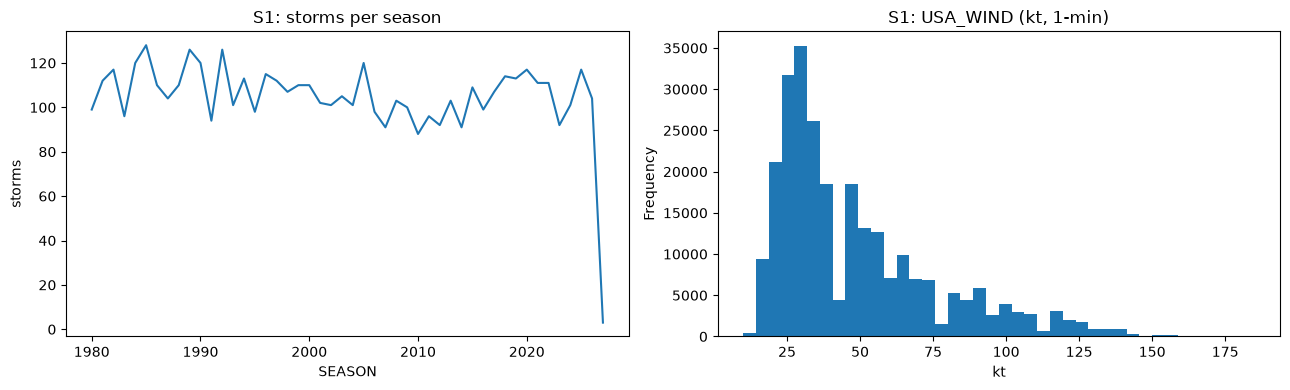

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s1.groupby("SEASON").SID.nunique().plot(ax=ax[0], title="S1: storms per season")
ax[0].set_ylabel("storms")
s1.USA_WIND.dropna().plot.hist(bins=40, ax=ax[1], title="S1: USA_WIND (kt, 1-min)")
ax[1].set_xlabel("kt"); plt.tight_layout(); plt.show()

## 4. S3 — IBTrACS ACTIVE (incremental)

In [40]:
s3_path = SAMPLES / "ibtracs_active.csv"
s3 = ibtracs.read_csv(s3_path)
print("Rows:", len(s3), "| active storms:", s3.SID.nunique(), "| last fix:", s3.ISO_TIME.max())
print("Validators:", json.loads((SAMPLES / "ibtracs_active.csv.meta.json").read_text())["headers"])
display(s3.groupby(["SID", "NAME", "BASIN"]).agg(fixes=("ISO_TIME", "size"), first=("ISO_TIME", "min"),
        last=("ISO_TIME", "max"), max_wind=("USA_WIND", "max")).reset_index())
display(profile(s3))      # full file: it holds fewer than 200 records when few storms are active
SUMMARY["S3"] = record_checks(s3, ["SID", "ISO_TIME"], "ISO_TIME", "LAT", "LON", "WMO_WIND")
print("TRACK_TYPE:", s3.TRACK_TYPE.value_counts().to_dict())
SUMMARY["S3"]

Rows: 139 | active storms: 3 | last fix: 2026-11-12 00:00:00+00:00
Validators: {'Content-Type': 'text/csv', 'Content-Length': '67175', 'Last-Modified': 'Thu, 12 Nov 2026 10:05:25 GMT', 'ETag': '"10667-66011734911b2"', 'Date': 'Sat, 14 Nov 2026 18:31:11 GMT'}


,SID,NAME,BASIN,fixes,first,last,max_wind
0,2026307N08230,PENA,EP,77,2026-11-02 12:00:00+00:00,2026-11-12 00:00:00+00:00,50
1,2026310N18149,CEMPAKA,WP,43,2026-11-06 06:00:00+00:00,2026-11-11 12:00:00+00:00,93
2,2026312S13053,UNNAMED,SI,19,2026-11-07 18:00:00+00:00,2026-11-10 00:00:00+00:00,39


,field,dtype,null_%,distinct,min,max,example
0,SID,str,0.0,3,NaN,NaN,2026307N08230
1,SEASON,int64,0.0,2,2.026000e+03,2.027000e+03,2026
2,NUMBER,int64,0.0,3,9.300000e+01,9.500000e+01,93
3,BASIN,str,0.0,3,NaN,NaN,EP
4,SUBBASIN,str,0.0,2,NaN,NaN,MM
5,NAME,str,0.0,3,NaN,NaN,PENA
6,ISO_TIME,"datetime64[us, UTC]",0.0,77,1.793621e+15,1.794442e+15,2026-11-02 12:00:00+00:00
7,NATURE,str,0.0,3,NaN,NaN,DS
8,LAT,float64,0.0,88,-1.350000e+01,3.020000e+01,7.7
9,LON,float64,0.0,130,-1.699000e+02,1.541000e+02,-129.8


TRACK_TYPE: {'PROVISIONAL': 139}


records                                         139
duplicated_ids                                    0
timestamp_parse_rate_%                        100.0
timestamp_example_raw     2026-11-02 12:00:00+00:00
lat_range                             (-13.5, 30.2)
lon_range                           (-169.9, 154.1)
invalid_lat                                       0
lon_outside_-180_180                              0
severity_range                           (nan, nan)
severity_null_%                               100.0
dtype: object

## 5. S2 — GDACS tropical-cyclone archive (historical)
First a **coverage probe** (one January window per year) to find where the TC archive starts, then the full profile of `GDACS_YEAR`.

In [41]:
probe_client = PoliteClient(min_interval=1.0)
probe_dir = RAW / "gdacs_tc_archive" / "coverage_probe"
coverage = []
for y in [1995, 2000, 2003, 2005, 2008, 2010, 2015, 2020]:
    res = probe_client.fetch_to_file(gdacs.SEARCH_URL, probe_dir / f"probe_{y}.json",
                                     params=gdacs.search_params(date(y, 1, 1), date(y, 12, 31)))
    n = len(gdacs.load_features(res.path)) if res.status == 200 and res.path else 0
    coverage.append({"year": y, "status": res.status, "features_page1": n})
coverage = pd.DataFrame(coverage); coverage.to_csv(EVIDENCE / "gdacs_coverage_probe.csv", index=False)
coverage

,year,status,features_page1
0,1995,204,0
1,2000,204,0
2,2003,204,0
3,2005,204,0
4,2008,200,1
5,2010,204,0
6,2015,200,100
7,2020,200,100


In [42]:
s2_files = sorted((RAW / "gdacs_tc_archive").glob(f"*/gdacs_tc_{GDACS_YEAR}-*_p*.json"))
s2_feats = [f for p in s2_files for f in gdacs.load_features(p)]
s2 = gdacs.features_to_frame(s2_feats)
print(f"Pages: {len(s2_files)} | features: {len(s2)} | distinct eventid: {s2.eventid.nunique()}")
print("Page sizes (features per page):", sorted({len(gdacs.load_features(p)) for p in s2_files}))
print("Raw property keys:", sorted(s2_feats[0]["properties"].keys()) if s2_feats else "none")
display(profile(s2))
SUMMARY["S2"] = record_checks(s2, ["eventid", "episodeid"], "todate", "lat", "lon", "severity")
print("severityunit values:", s2.severityunit.value_counts(dropna=False).to_dict())
print("alertlevel values  :", s2.alertlevel.value_counts(dropna=False).to_dict())
print("geometry types     :", s2.geom_type.value_counts(dropna=False).to_dict())
SUMMARY["S2"]

Pages: 48 | features: 106 | distinct eventid: 92
Page sizes (features per page): [0, 2, 3, 4, 5, 6, 8, 9, 13, 15, 16, 20]
Raw property keys: ['Class', 'affectedcountries', 'alertlevel', 'alertscore', 'country', 'countryonland', 'datemodified', 'description', 'episodealertlevel', 'episodealertscore', 'episodeid', 'eventid', 'eventname', 'eventtype', 'fromdate', 'glide', 'htmldescription', 'icon', 'iconoverall', 'iscurrent', 'iso3', 'istemporary', 'name', 'polygonlabel', 'severitydata', 'source', 'sourceid', 'todate', 'url']


,field,dtype,null_%,distinct,min,max,example
0,eventtype,str,0.0,1,NaN,NaN,TC
1,eventid,int64,0.0,92,1001040.000,1.001134e+06,1001045
2,episodeid,int64,0.0,36,3.000,4.800000e+01,11
3,eventname,str,0.0,92,NaN,NaN,05-20232024-24
4,glide,str,85.8,12,NaN,NaN,TC-2024-000032-MOZ
5,name,str,0.0,92,NaN,NaN,Tropical Cyclone 05-20232024-24
6,description,str,0.0,92,NaN,NaN,Tropical Cyclone 05-20232024-24
7,htmldescription,str,0.0,92,NaN,NaN,Green Tropical Cyclone 05-20232024-24 off-shor...
8,icon,str,0.0,3,NaN,NaN,https://www.gdacs.org/images/gdacs_icons/maps/...
9,iconoverall,str,0.0,3,NaN,NaN,https://www.gdacs.org/images/gdacs_icons/maps/...


severityunit values: {'km/h': 106}
alertlevel values  : {'Green': 73, 'Orange': 20, 'Red': 13}
geometry types     : {'Point': 106}


records                                   106
duplicated_ids                             14
timestamp_parse_rate_%                  100.0
timestamp_example_raw     2024-02-02T06:00:00
lat_range                      (-33.09, 49.0)
lon_range                     (-179.2, 179.3)
invalid_lat                                 0
lon_outside_-180_180                        0
severity_range             (46.296, 287.0352)
severity_null_%                           0.0
dtype: object

## 6. S4 — GDACS current tropical cyclones (incremental, last 7 days)

In [43]:
s4_files = sorted(SAMPLES.glob("gdacs_tc_current_*.json"))
s4 = gdacs.features_to_frame([f for p in s4_files for f in gdacs.load_features(p)])
print("Files:", [p.name for p in s4_files], "| features:", len(s4))
if s4.empty:
    print("Empty response: a valid state (no TC events in the window). Keep the raw file as evidence.")
else:
    display(s4[[c for c in ["eventid", "episodeid", "name", "alertlevel", "fromdate", "todate",
                            "datemodified", "iscurrent", "severity", "severityunit", "lat", "lon"] if c in s4]])
    display(profile(s4))
    SUMMARY["S4"] = record_checks(s4, ["eventid", "episodeid"], "todate", "lat", "lon", "severity")

Files: ['gdacs_tc_current_gdacs_tc_2026-11-07_2026-11-14_p01.json', 'gdacs_tc_current_gdacs_tc_2026-11-07_2026-11-14_p01.json.meta.json'] | features: 3


,eventid,episodeid,name,alertlevel,fromdate,todate,datemodified,iscurrent,severity,severityunit,lat,lon
0,1001348,24,Tropical Cyclone PENA-26,Green,2026-11-06T21:00:00,2026-11-12T15:00:00,2026-11-12T14:52:09,true,92.592000,km/h,9.8,-173.40
1,1001347,22,Tropical Cyclone CEMPAKA-26,Green,2026-11-06T06:00:00,2026-11-11T12:00:00,2026-11-13T00:50:32,true,175.924800,km/h,30.2,154.10
2,1001349,6,Tropical Cyclone 02-20262027-27,Green,2026-11-07T06:00:00,2026-11-08T12:00:00,2026-11-09T19:35:36,false,63.332928,km/h,-11.8,50.54


,field,dtype,null_%,distinct,min,max,example
0,eventtype,str,0.0,1,NaN,NaN,TC
1,eventid,int64,0.0,3,1.001347e+06,1.001349e+06,1001348
2,episodeid,int64,0.0,3,6.000000e+00,2.400000e+01,24
3,eventname,str,0.0,3,NaN,NaN,PENA-26
4,glide,str,100.0,1,NaN,NaN,None
5,name,str,0.0,3,NaN,NaN,Tropical Cyclone PENA-26
6,description,str,0.0,3,NaN,NaN,Tropical Cyclone PENA-26
7,htmldescription,str,0.0,3,NaN,NaN,Green Tropical Cyclone PENA-26 off-shore from:...
8,icon,str,0.0,1,NaN,NaN,https://www.gdacs.org/images/gdacs_icons/maps/...
9,iconoverall,str,0.0,1,NaN,NaN,https://www.gdacs.org/images/gdacs_icons/maps/...


## 7. S5 — NHC CurrentStorms.json (optional)

In [44]:
p = SAMPLES / "nhc_CurrentStorms.json"
if p.exists():
    s5 = nhc.storms_to_frame(nhc.load(p))
    print("Active NHC storms:", len(s5))
    display(s5 if not s5.empty else pd.DataFrame({"note": ["activeStorms is empty - valid response"]}))

Active NHC storms: 0


,note
0,activeStorms is empty - valid response


## 8. Data-quality problems (at least five, each with an example record)
Each check searches the real data for the problem; the example record is printed and saved to
`workshop_1/evidence/dq_examples.csv`. A check that finds nothing is reported as **not observed** — do not invent it.

In [45]:
dq = []

def add(dq_id, source, problem, mask_or_df, cols):
    ex = mask_or_df if isinstance(mask_or_df, pd.DataFrame) else None
    if ex is None or ex.empty:
        dq.append({"id": dq_id, "source": source, "problem": problem, "observed": False, "count": 0, "example": None})
    else:
        rec = ex.iloc[0][[c for c in cols if c in ex.columns]].to_dict()
        dq.append({"id": dq_id, "source": source, "problem": problem, "observed": True,
                   "count": len(ex), "example": json.dumps(rec, default=str)})

# DQ1 mixed wind averaging periods: fixes with WMO_WIND from a non-US agency and no USA_WIND
add("DQ1", "S1", "Wind from a 10-min agency without a 1-min USA_WIND",
    s1[s1.USA_WIND.isna() & s1.WMO_WIND.notna()], ["SID", "ISO_TIME", "BASIN", "WMO_AGENCY", "WMO_WIND", "USA_WIND"])
# DQ2 blanks / units row
blank_rows = s1_raw[s1_raw["WMO_WIND"].str.strip() == ""]
add("DQ2", "S1", "Missing numeric values written as blank strings" +
    (" + units header row" if s1_raw.attrs.get("units_row") is not None else ""),
    blank_rows, ["SID", "ISO_TIME", "WMO_WIND", "WMO_PRES"])
# DQ3 spur / provisional tracks
add("DQ3", "S1", "Spur track types (position disagreement)", s1[s1.TRACK_TYPE.str.contains("spur", case=False, na=False)],
    ["SID", "ISO_TIME", "TRACK_TYPE", "LAT", "LON"])
add("DQ3b", "S3", "Provisional fixes subject to revision", s3[s3.TRACK_TYPE.str.contains("PROVISIONAL", na=False)],
    ["SID", "ISO_TIME", "TRACK_TYPE", "USA_AGENCY", "USA_WIND"])
# DQ4 multiple ATCF ids / unnamed storms
add("DQ4", "S1", "Several ATCF ids joined by ':'", s1[s1.USA_ATCF_ID.str.contains(":", na=False)],
    ["SID", "NAME", "USA_ATCF_ID"])
add("DQ4b", "S1", "Placeholder name for unnamed storms", s1[s1.NAME.str.contains("NOT_NAMED|UNNAMED", na=False)],
    ["SID", "SEASON", "BASIN", "NAME"])
# DQ5 GDACS timestamps without offset; severity unit
if not s2.empty:
    add("DQ5", "S2", "Timestamp string without time-zone designator",
        s2[~s2.todate.astype(str).str.contains(r"Z$|[+-]\d\d:?\d\d$", regex=True, na=False)],
        ["eventid", "episodeid", "fromdate", "todate", "datemodified"])
    add("DQ5b", "S2", "Severity not in knots", s2[~s2.severityunit.astype(str).str.contains("kt|knot", case=False, na=False)],
        ["eventid", "name", "severity", "severityunit", "severitytext"])
    # DQ6 several episodes per event in the window
    multi = s2[s2.duplicated("eventid", keep=False)].sort_values(["eventid", "episodeid"])
    add("DQ6", "S2", "Same storm represented by several episodes/features", multi,
        ["eventid", "episodeid", "name", "alertlevel", "todate"])
# DQ7 out-of-range / outlier positions or winds
add("DQ7", "S1", "Longitude outside [-180, 180] (needs normalization)", s1[~s1.LON.between(-180, 180)],
    ["SID", "ISO_TIME", "LAT", "LON"])

dq = pd.DataFrame(dq); dq.to_csv(EVIDENCE / "dq_examples.csv", index=False)
print("Observed problems:", int(dq.observed.sum()), "of", len(dq))
dq

Observed problems: 9 of 10


,id,source,problem,observed,count,example
0,DQ1,S1,Wind from a 10-min agency without a 1-min USA_...,True,12690,"{""SID"": ""1980002S15081"", ""ISO_TIME"": ""1980-01-..."
1,DQ2,S1,Missing numeric values written as blank string...,True,191391,"{""SID"": ""1980001S13173"", ""ISO_TIME"": ""1980-01-..."
2,DQ3,S1,Spur track types (position disagreement),True,1169,"{""SID"": ""1980002S15081"", ""ISO_TIME"": ""1980-01-..."
3,DQ3b,S3,Provisional fixes subject to revision,True,139,"{""SID"": ""2026307N08230"", ""ISO_TIME"": ""2026-11-..."
4,DQ4,S1,Several ATCF ids joined by ':',False,0,NaN
5,DQ4b,S1,Placeholder name for unnamed storms,True,38257,"{""SID"": ""1980010S20043"", ""SEASON"": 1980, ""BASI..."
6,DQ5,S2,Timestamp string without time-zone designator,True,106,"{""eventid"": 1001045, ""episodeid"": 11, ""fromdat..."
7,DQ5b,S2,Severity not in knots,True,106,"{""eventid"": 1001045, ""name"": ""Tropical Cyclone..."
8,DQ6,S2,Same storm represented by several episodes/fea...,True,28,"{""eventid"": 1001043, ""episodeid"": 14, ""name"": ..."
9,DQ7,S1,"Longitude outside [-180, 180] (needs normaliza...",True,7639,"{""SID"": ""1980001S13173"", ""ISO_TIME"": ""1980-01-..."


## 9. Cross-source overlap (IBTrACS ↔ GDACS)
For each GDACS feature of `GDACS_YEAR`, find the nearest IBTrACS fix within ±6 h and report the distance and differences.
Thresholds (6 h, 150 km) are a starting proposal. GDACS times are **assumed UTC** here — if the time differences cluster
around a constant offset, that reveals a time-zone problem (record it in the report).

GDACS features matched within 6 h & 150 km: 88 of 106


,ibtracs_sid,ibtracs_name,ibtracs_time,ibtracs_wind_kt,gdacs_eventid,gdacs_episodeid,gdacs_name,gdacs_time,gdacs_severity_kt,dt_hours,dist_km,dsev_kt
75,2024295N15092,DANA,2024-10-25 00:00:00+00:00,55.0,1001117,8,Tropical Cyclone DANA-24,2024-10-25 00:00:00+00:00,64.994384,0.0,0.0,9.994384
51,2024213N14254,CARLOTTA,2024-08-06 03:00:00+00:00,38.0,1001074,23,Tropical Cyclone CARLOTTA-24,2024-08-06 03:00:00+00:00,79.993089,0.0,0.0,41.993089
42,2024225N14313,ERNESTO,2024-08-20 15:00:00+00:00,58.0,1001080,36,Tropical Cyclone ERNESTO-24,2024-08-20 15:00:00+00:00,84.992657,0.0,0.0,26.992657
28,2024213N14254,CARLOTTA,2024-08-06 03:00:00+00:00,38.0,1001074,23,Tropical Cyclone CARLOTTA-24,2024-08-06 03:00:00+00:00,79.993089,0.0,0.0,41.993089
101,2024359S13097,UNNAMED,2024-12-28 06:00:00+00:00,29.0,1001133,4,Tropical Cyclone FIVE-24,2024-12-28 06:00:00+00:00,34.996976,0.0,0.0,5.996976
100,2024364S17177,UNNAMED,2024-12-30 00:00:00+00:00,35.0,1001134,4,Tropical Cyclone SIX-24,2024-12-30 00:00:00+00:00,49.995680,0.0,0.0,14.995680
79,2024279N21265,MILTON,2024-10-10 21:00:00+00:00,60.0,1001111,23,Tropical Cyclone MILTON-24,2024-10-10 21:00:00+00:00,154.986609,0.0,0.0,94.986609
80,2024278N11150,BARIJAT,2024-10-10 06:00:00+00:00,40.0,1001112,15,Tropical Cyclone BARIJAT-24,2024-10-10 06:00:00+00:00,44.996112,0.0,0.0,4.996112
88,2024328S09096,ROBYN,2024-11-29 12:00:00+00:00,35.0,1001129,5,Tropical Cyclone ROBYN-24,2024-11-29 12:00:00+00:00,49.995680,0.0,0.0,14.995680
3,2024022S16058,CANDICE,2024-01-27 06:00:00+00:00,30.0,1001044,13,Tropical Cyclone CANDICE-24,2024-01-27 06:00:00+00:00,56.995076,0.0,6.3,26.995076


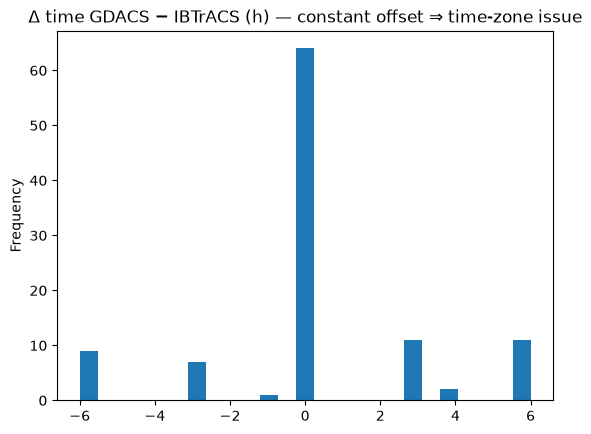

In [46]:
pairs = []
ib = s1[s1.SEASON.between(GDACS_YEAR - 1, GDACS_YEAR + 1)].copy()
ib["lat_c"] = ib.USA_LAT.fillna(ib.LAT); ib["lon_c"] = ib.USA_LON.fillna(ib.LON)
g = s2.copy(); g["t"] = pd.to_datetime(g.todate, errors="coerce").dt.tz_localize("UTC")
for _, r in g.dropna(subset=["t", "lat", "lon"]).iterrows():
    win = ib[(ib.ISO_TIME - r.t).abs() <= pd.Timedelta(hours=6)]
    if win.empty:
        continue
    d = haversine_km(r.lat, r.lon, win.lat_c.to_numpy(), win.lon_c.to_numpy())
    j = int(np.argmin(d)); best = win.iloc[j]
    sev_kt = r.severity / KMH_PER_KT if "km" in str(r.severityunit).lower() else r.severity
    pairs.append({
        "ibtracs_sid": best.SID, "ibtracs_name": best.NAME, "ibtracs_time": best.ISO_TIME,
        "ibtracs_wind_kt": best.USA_WIND if pd.notna(best.USA_WIND) else best.WMO_WIND,
        "gdacs_eventid": r.eventid, "gdacs_episodeid": r.episodeid, "gdacs_name": r.get("name"),
        "gdacs_time": r.t, "gdacs_severity_kt": sev_kt,
        "dt_hours": (r.t - best.ISO_TIME).total_seconds() / 3600, "dist_km": round(float(d[j]), 1),
        "dsev_kt": (sev_kt - (best.USA_WIND if pd.notna(best.USA_WIND) else best.WMO_WIND)),
    })
pairs = pd.DataFrame(pairs)
cand = pairs[pairs.dist_km <= 150].sort_values("dist_km") if not pairs.empty else pairs
cand.to_csv(EVIDENCE / "overlap_pairs.csv", index=False)
print(f"GDACS features matched within 6 h & 150 km: {len(cand)} of {len(g)}")
display(cand.head(10))
if not pairs.empty:
    pairs.dt_hours.plot.hist(bins=25, title="Δ time GDACS − IBTrACS (h) — constant offset ⇒ time-zone issue"); plt.show()

## 10. Volume estimates and partitioning

In [47]:
vol = {
    "S1 file size (MB)": round(s1_path.stat().st_size / 1e6, 1),
    "S1 rows (fixes)": len(s1),
    "S1 storms": s1.SID.nunique(),
    "S1 rows per season (median)": int(s1.groupby("SEASON").size().median()),
    "S1 partitions SEASON x BASIN": s1.groupby(["SEASON", "BASIN"]).ngroups,
    "S2 features in GDACS_YEAR": len(s2),
    "S2 pages in GDACS_YEAR": len(s2_files),
    "S2 bytes in GDACS_YEAR (MB)": round(sum(p.stat().st_size for p in s2_files) / 1e6, 2),
}
first_year = coverage[coverage.features_page1 > 0].year.min() if (coverage.features_page1 > 0).any() else None
if first_year:
    years = datetime.now(timezone.utc).year - int(first_year) + 1
    vol["S2 coverage probe: first year with TC features"] = int(first_year)
    vol["S2 estimated total features (x years)"] = int(len(s2) * years)
    vol["S2 estimated total requests (monthly windows)"] = int(12 * years)
pd.Series(vol)

S1 file size (MB)                                    145.40
S1 rows (fixes)                                   312394.00
S1 storms                                           5017.00
S1 rows per season (median)                         6473.00
S1 partitions SEASON x BASIN                         287.00
S2 features in GDACS_YEAR                            106.00
S2 pages in GDACS_YEAR                                48.00
S2 bytes in GDACS_YEAR (MB)                            0.17
S2 coverage probe: first year with TC features      2008.00
S2 estimated total features (x years)               2014.00
S2 estimated total requests (monthly windows)        228.00
dtype: float64

## 11. Summary table for the report (Section 4.1)

In [48]:
summary = pd.DataFrame(SUMMARY)
summary.to_csv(EVIDENCE / "profile_summary.csv")
summary

,S1,S3,S2,S4
records,312394,139,106,3
duplicated_ids,0,0,14,0
timestamp_parse_rate_%,100.0,100.0,100.0,100.0
timestamp_example_raw,1980-01-01 00:00:00+00:00,2026-11-02 12:00:00+00:00,2024-02-02T06:00:00,2026-11-12T15:00:00
lat_range,"(-68.5, 70.7)","(-13.5, 30.2)","(-33.09, 49.0)","(-11.8, 30.2)"
lon_range,"(-179.8, 266.9)","(-169.9, 154.1)","(-179.2, 179.3)","(-173.4, 154.1)"
invalid_lat,0,0,0,0
lon_outside_-180_180,7639,0,0,0
severity_range,"(3.0, 185.0)","(nan, nan)","(46.296, 287.0352)","(63.332928, 175.9248)"
severity_null_%,61.3,100.0,0.0,0.0


## 12. Conclusions (run of 2026-11-14, 19:05 UTC)

**Sources validated (all real queries answered).** S1 IBTrACS `since1980` (HTTP 200, 145.4 MB, release of 12 Nov 2026), S2 GDACS TC archive (12 monthly pages HTTP 200 + 12 end-of-results HTTP 204), S3 IBTrACS `ACTIVE` (HTTP 200, 67 KB; conditional GET returned 304 in poll 2), S4 GDACS TC last 7 days (HTTP 200, 3 features), S5 NHC (HTTP 200, valid empty feed).

**Confirmed quirks.**
- IBTrACS: units row on line 2; missing values are a single space; `LON` reaches 266.9° (7,639 fixes > 180); `TRACK_TYPE` values are `main`, `PROVISIONAL`, `US-PROVISIONAL`, `spur-merge`, `spur-split`, `spur-other`, `US-PROVISIONAL_spur`; (`SID`, `ISO_TIME`) has 0 duplicates in 312,394 fixes.
- GDACS: page size 100; end of results = HTTP 204; no ETag / Last-Modified / rate-limit headers; timestamps without offset are UTC (64 of 88 matched pairs at Δt = 0 h); `severity` is in km/h for all features and equals the storm's peak wind so far, not the current intensity (CEMPAKA 95 kt vs IBTrACS peak 93 kt and current 64 kt).
- GDACS coverage probe: no TC events for 1995, 2000, 2003, 2005, 2010; 1 for 2008; full pages for 2015 and 2020 → GDACS used from 2015.

**Data-quality problems observed (8).** Mixed wind averaging periods (12,690 fixes), units row + blank strings (191,391 fixes with blank WMO_WIND), spur tracks (1,169), provisional data (S1 10,811; S3 all 139), placeholder names `UNNAMED` (38,257) vs GDACS labels such as `FIVE-24`, longitudes > 180 (7,639), GDACS timestamps without zone and km/h severity (106/106), month-window duplicates (14 in 2024). Not observed: ATCF IDs joined by ':'.

**Overlap.** 88 of 106 GDACS 2024 features match an IBTrACS fix within ±6 h and 150 km (median 24.1 km); the three active storms appear in both S3 and S4.

**Decisions carried to the ingestion contract.** Duplicate keys (`SID`, `ISO_TIME`) and (`eventid`, `episodeid`) with cross-window dedupe; watermarks ETag/Last-Modified (IBTrACS) and `datemodified` (GDACS) with a 72 h overlap; GDACS severity stored as `tc_alert.peak_wind_kt`.

*Note on section 5 output:* the printed "Pages: 48" and the page-size list count the `.meta.json` sidecars, which also match the `*.json` pattern (they hold no features, so feature counts are unaffected). The real number of GDACS archive responses for 2024 is 24: 12 data pages and 12 empty HTTP 204 pages (`evidence/access_log.csv`). The same applies to the S4 file list.
